In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('athlete_events.csv')
df.head()

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN


In [13]:
"""
New columns:
-Athlete_Medal_Count: Count of medals by athlete (ID needed because of possibility of duplicate names)
-Athlete_OneGame_Medal_Count: Count of medals by athlete for a single Games
-NOC_Medal_Count: Count of medals by NOC
-NOC_OneGame_Medal_Count: Count of medals by NOC for a single Games

-Gold_Medal_Flag: Indicates Gold Medal or not
-Silver_Medal_Flag: Indicates Silver Medal or not
-Bronze_Medal_Flag: Indicates Bronze Medal or not
"""
df['Athlete_Medal_Count'] = df.groupby(['ID','Name'])['Medal'].transform('count')
df['Athlete_OneGame_Medal_Count'] = df.groupby(['ID','Name','Games'])['Medal'].transform('count')
df['NOC_Medal_Count'] = df.groupby(['NOC'])['Medal'].transform('count')
df['NOC_OneGame_Medal_Count'] = df.groupby(['Games','NOC'])['Medal'].transform('count')

df['Gold_Medal_Flag'] = df['Medal'].map({'Gold': 1})
df['Silver_Medal_Flag'] = df['Medal'].map({'Silver': 1})
df['Bronze_Medal_Flag'] = df['Medal'].map({'Bronze': 1})

In [14]:
df.head()

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,...,Sport,Event,Medal,Athlete_Medal_Count,Athlete_OneGame_Medal_Count,NOC_Medal_Count,NOC_OneGame_Medal_Count,Gold_Medal_Flag,Silver_Medal_Flag,Bronze_Medal_Flag
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,...,Basketball,Basketball Men's Basketball,NaN,0,0,989,82,NaN,NaN,NaN
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,...,Judo,Judo Men's Extra-Lightweight,NaN,0,0,989,125,NaN,NaN,NaN
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,...,Football,Football Men's Football,NaN,0,0,597,71,NaN,NaN,NaN
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,...,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold,1,1,597,9,1.0,NaN,NaN
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,...,Speed Skating,Speed Skating Women's 500 metres,NaN,0,0,1040,7,NaN,NaN,NaN


In [15]:
noc_medal_counts = df.loc[:, ['NOC', 'NOC_Medal_Count']].drop_duplicates().sort_values(by='NOC_Medal_Count', ascending=False)
noc_medal_counts.head(10)

,NOC,NOC_Medal_Count
10,USA,5637
192,URS,2503
261,GER,2165
785,GBR,2068
98,FRA,1777
158,ITA,1637
725,SWE,1536
269,CAN,1352
274,AUS,1320
163,RUS,1165


In [16]:
noc_onegame_medal_counts = df.loc[:, ['NOC', 'Games', 'NOC_OneGame_Medal_Count']].drop_duplicates().sort_values(by='NOC_OneGame_Medal_Count', ascending=False)
noc_onegame_medal_counts[noc_onegame_medal_counts.Games=='2016 Summer'].head(10)
#not exactly accurate

,NOC,Games,NOC_OneGame_Medal_Count
282,USA,2016 Summer,264
704,GER,2016 Summer,159
1495,GBR,2016 Summer,145
615,RUS,2016 Summer,115
2612,CHN,2016 Summer,113
175,FRA,2016 Summer,96
813,AUS,2016 Summer,82
158,ITA,2016 Summer,72
685,CAN,2016 Summer,69
1331,JPN,2016 Summer,64


In [21]:
df[(df.Games=='2016 Summer') & (df.NOC=='USA')].loc[:, ['NOC', 'Games', 'Medal']].groupby(['NOC', 'Games']).count()

,,Medal
NOC,Games,
USA,2016 Summer,264


In [22]:
df['Medal'].unique()

array([nan, 'Gold', 'Bronze', 'Silver'], dtype=object)

In [25]:
df[(df.Games=='2016 Summer') & (df.NOC=='USA')].count()

ID                             719
Name                           719
Sex                            719
Age                            719
Height                         718
Weight                         718
Team                           719
NOC                            719
Games                          719
Year                           719
Season                         719
City                           719
Sport                          719
Event                          719
Medal                          264
Athlete_Medal_Count            719
Athlete_OneGame_Medal_Count    719
NOC_Medal_Count                719
NOC_OneGame_Medal_Count        719
Gold_Medal_Flag                139
Silver_Medal_Flag               54
Bronze_Medal_Flag               71
dtype: int64

In [26]:
bool_series = pd.notnull(df["Medal"])

In [27]:
df[bool_series]

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,...,Sport,Event,Medal,Athlete_Medal_Count,Athlete_OneGame_Medal_Count,NOC_Medal_Count,NOC_OneGame_Medal_Count,Gold_Medal_Flag,Silver_Medal_Flag,Bronze_Medal_Flag
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,...,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold,1,1,597,9,1.0,NaN,NaN
37,15,Arvo Ossian Aaltonen,M,30.0,NaN,NaN,Finland,FIN,1920 Summer,1920,...,Swimming,Swimming Men's 200 metres Breaststroke,Bronze,2,2,900,52,NaN,NaN,1.0
38,15,Arvo Ossian Aaltonen,M,30.0,NaN,NaN,Finland,FIN,1920 Summer,1920,...,Swimming,Swimming Men's 400 metres Breaststroke,Bronze,2,2,900,52,NaN,NaN,1.0
40,16,Juhamatti Tapio Aaltonen,M,28.0,184.0,85.0,Finland,FIN,2014 Winter,2014,...,Ice Hockey,Ice Hockey Men's Ice Hockey,Bronze,1,1,900,33,NaN,NaN,1.0
41,17,Paavo Johannes Aaltonen,M,28.0,175.0,64.0,Finland,FIN,1948 Summer,1948,...,Gymnastics,Gymnastics Men's Individual All-Around,Bronze,5,4,900,33,NaN,NaN,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
271078,135553,Galina Ivanovna Zybina (-Fyodorova),F,25.0,168.0,80.0,Soviet Union,URS,1956 Summer,1956,...,Athletics,Athletics Women's Shot Put,Silver,3,1,2503,169,NaN,1.0,NaN
271080,135553,Galina Ivanovna Zybina (-Fyodorova),F,33.0,168.0,80.0,Soviet Union,URS,1964 Summer,1964,...,Athletics,Athletics Women's Shot Put,Bronze,3,1,2503,174,NaN,NaN,1.0
271082,135554,Bogusaw Zych,M,28.0,182.0,82.0,Poland,POL,1980 Summer,1980,...,Fencing,"Fencing Men's Foil, Team",Bronze,1,1,565,50,NaN,NaN,1.0
271102,135563,Olesya Nikolayevna Zykina,F,19.0,171.0,64.0,Russia,RUS,2000 Summer,2000,...,Athletics,Athletics Women's 4 x 400 metres Relay,Bronze,2,1,1165,187,NaN,NaN,1.0


In [39]:
athlete_medal_counts = df.loc[:, ['Name', 'Sex', 'Season', 'Medal_Count']].drop_duplicates().sort_values(by='Medal_Count')
athlete_medal_counts
#removing sport to account for multi-sport athletes
#adding sex for medals by gender

,Name,Sex,Season,Medal_Count
0,A Dijiang,M,Summer,0
169043,Douglas Mortimer Lewes Neame,M,Summer,0
169030,"Charles R. ""Jack"" Neale",M,Summer,0
169023,Ian G. Neale,M,Summer,0
169022,"William ""Bill"" Neale",M,Winter,0
...,...,...,...,...
22698,Ole Einar Bjrndalen,M,Winter,13
217312,Borys Anfiyanovych Shakhlin,M,Summer,13
7510,Nikolay Yefimovich Andrianov,M,Summer,15
133184,Larysa Semenivna Latynina (Diriy-),F,Summer,18


In [40]:
#Check if athletes with same name are aggregated (they are not, thankfully)
athlete_medal_counts[athlete_medal_counts.Name=='Takashi Ono']

,Name,Sex,Season,Medal_Count
177440,Takashi Ono,M,Summer,0
177408,Takashi Ono,M,Summer,13


In [41]:
athlete_medal_counts = athlete_medal_counts[athlete_medal_counts.Medal_Count>0]
athlete_medal_counts

,Name,Sex,Season,Medal_Count
100365,"Anthony Francis ""Fran"" Huck",M,Winter,1
23339,Viktor Nikolayevich Blinov,M,Winter,1
23366,Alfred Bloch,M,Summer,1
137567,Yuliya Aleksandrovna Levina,F,Summer,1
137560,John Gustaf Hjalmar Levin,M,Summer,1
...,...,...,...,...
22698,Ole Einar Bjrndalen,M,Winter,13
217312,Borys Anfiyanovych Shakhlin,M,Summer,13
7510,Nikolay Yefimovich Andrianov,M,Summer,15
133184,Larysa Semenivna Latynina (Diriy-),F,Summer,18


In [42]:
summer_athlete_medal_counts = athlete_medal_counts[athlete_medal_counts.Season=='Summer']
winter_athlete_medal_counts = athlete_medal_counts[athlete_medal_counts.Season=='Winter']

In [43]:
summer_athlete_medal_counts

,Name,Sex,Season,Medal_Count
23366,Alfred Bloch,M,Summer,1
137567,Yuliya Aleksandrovna Levina,F,Summer,1
137560,John Gustaf Hjalmar Levin,M,Summer,1
140788,Liu Yang,M,Summer,1
138818,Gertrude Liebhart (-Fischer),F,Summer,1
...,...,...,...,...
177408,Takashi Ono,M,Summer,13
217312,Borys Anfiyanovych Shakhlin,M,Summer,13
7510,Nikolay Yefimovich Andrianov,M,Summer,15
133184,Larysa Semenivna Latynina (Diriy-),F,Summer,18


In [44]:
winter_athlete_medal_counts

,Name,Sex,Season,Medal_Count
100365,"Anthony Francis ""Fran"" Huck",M,Winter,1
23339,Viktor Nikolayevich Blinov,M,Winter,1
236698,Gottlieb Taschler,M,Winter,1
233714,Thomas Sykora,M,Winter,1
23340,Yury Ivanovich Blinov,M,Winter,1
...,...,...,...,...
56098,"Ursula ""Uschi"" Disl",F,Winter,9
22666,Marit Bjrgen,F,Winter,10
223209,Raisa Petrovna Smetanina,F,Winter,10
18375,Stefania Belmondo,F,Winter,10


In [46]:
male_medal_counts = athlete_medal_counts[athlete_medal_counts.Sex=='M']
female_medal_counts = athlete_medal_counts[athlete_medal_counts.Sex=='F']

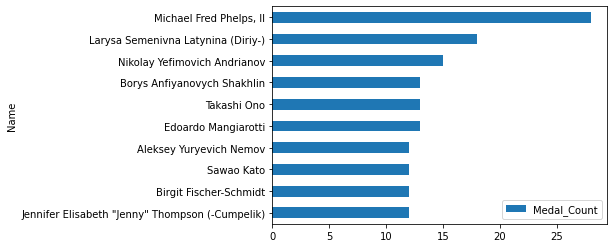

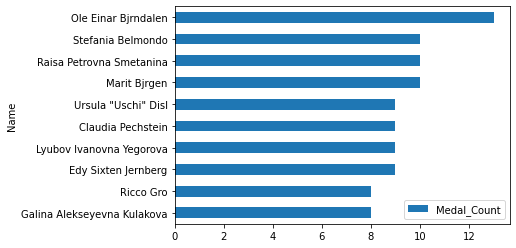

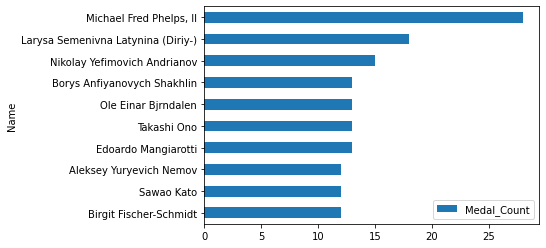

In [45]:
summer_top10 = summer_athlete_medal_counts.tail(10).plot.barh(x='Name', y='Medal_Count')
winter_top10 = winter_athlete_medal_counts.tail(10).plot.barh(x='Name', y='Medal_Count')
overall_top10 = athlete_medal_counts.tail(10).plot.barh(x='Name', y='Medal_Count')

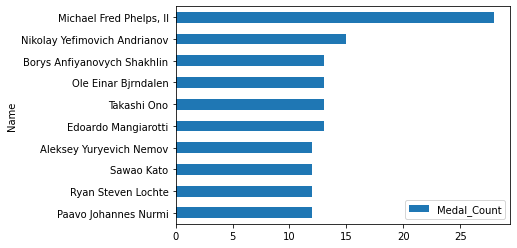

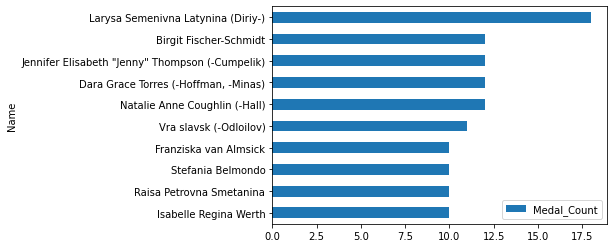

In [47]:
male_top10 = male_medal_counts.tail(10).plot.barh(x='Name', y='Medal_Count')
female_top10 = female_medal_counts.tail(10).plot.barh(x='Name', y='Medal_Count')

In [48]:
#Most medals at single Games
df['OneGame_Medal_Count'] = df.groupby(['ID','Name','Games'])['Medal'].transform('count')
df.head()

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal,Medal_Count,OneGame_Medal_Count
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN,0,0
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN,0,0
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN,0,0
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold,1,1
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN,0,0


In [58]:
df[df.OneGame_Medal_Count>5].loc[:, ['Name', 'Sex', 'Sport', 'Games', 'OneGame_Medal_Count']].drop_duplicates().sort_values(by='OneGame_Medal_Count', ascending=False)

,Name,Sex,Sport,Games,OneGame_Medal_Count
187888,"Michael Fred Phelps, II",M,Swimming,2004 Summer,8
56199,Aleksandr Nikolayevich Dityatin,M,Gymnastics,1980 Summer,8
187896,"Michael Fred Phelps, II",M,Swimming,2008 Summer,8
7518,Nikolay Yefimovich Andrianov,M,Gymnastics,1976 Summer,7
217320,Borys Anfiyanovych Shakhlin,M,Gymnastics,1960 Summer,7
22090,"Matthew Nicholas ""Matt"" Biondi",M,Swimming,1988 Summer,7
135507,"Willis Augustus Lee, Jr.",M,Shooting,1920 Summer,7
98812,Mariya Kindrativna Horokhovska,F,Gymnastics,1952 Summer,7
226662,Mark Andrew Spitz,M,Swimming,1972 Summer,7
226726,Lloyd Spencer Spooner,M,Shooting,1920 Summer,7


In [60]:
df['Gold_Medal'] = df['Medal'].map({'Gold': 1})
df.head()

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal,Medal_Count,OneGame_Medal_Count,Gold_Medal
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN,0,0,NaN
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN,0,0,NaN
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN,0,0,NaN
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold,1,1,1.0
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN,0,0,NaN


In [61]:
df['OneGame_GoldMedal_Count'] = df.groupby(['ID','Name','Games'])['Gold_Medal'].transform('count')
df.head()

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal,Medal_Count,OneGame_Medal_Count,Gold_Medal,OneGame_GoldMedal_Count
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN,0,0,NaN,0
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN,0,0,NaN,0
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN,0,0,NaN,0
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold,1,1,1.0,1
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN,0,0,NaN,0


In [64]:
df[df.OneGame_GoldMedal_Count>4].loc[:, ['Name', 'Sex', 'Sport', 'Games', 'OneGame_GoldMedal_Count']].drop_duplicates().sort_values(by='OneGame_GoldMedal_Count', ascending=False)

,Name,Sex,Sport,Games,OneGame_GoldMedal_Count
187896,"Michael Fred Phelps, II",M,Swimming,2008 Summer,8
226662,Mark Andrew Spitz,M,Swimming,1972 Summer,7
179153,Kristin Otto,F,Swimming,1988 Summer,6
187888,"Michael Fred Phelps, II",M,Swimming,2004 Summer,6
217832,Vitaly Venediktovich Shcherbo,M,Gymnastics,1992 Summer,6
22090,"Matthew Nicholas ""Matt"" Biondi",M,Swimming,1988 Summer,5
93166,Anton Heida,M,Gymnastics,1904 Summer,5
93199,Eric Arthur Heiden,M,Speed Skating,1980 Winter,5
135507,"Willis Augustus Lee, Jr.",M,Shooting,1920 Summer,5
167263,Nedo Nadi,M,Fencing,1920 Summer,5


In [75]:
df[(df.Sex=='F') & (df.OneGame_GoldMedal_Count>3)].loc[:, ['Name', 'Sex', 'Sport', 'Games', 'OneGame_GoldMedal_Count']].drop_duplicates().sort_values(by='OneGame_GoldMedal_Count', ascending=False)

,Name,Sex,Sport,Games,OneGame_GoldMedal_Count
179153,Kristin Otto,F,Swimming,1988 Summer,6
21758,Simone Arianne Biles,F,Gymnastics,2016 Summer,4
23132,"Francina Elsje ""Fanny"" Blankers-Koen",F,Athletics,1948 Summer,4
36625,Vra slavsk (-Odloilov),F,Gymnastics,1968 Summer,4
63527,"Kornelia Ender (-Matthes, -Grummt)",F,Swimming,1976 Summer,4
72307,"Melissa Jeanette ""Missy"" Franklin",F,Swimming,2012 Summer,4
115446,gnes Keleti-Srkny (Klein),F,Gymnastics,1956 Summer,4
133184,Larysa Semenivna Latynina (Diriy-),F,Gymnastics,1956 Summer,4
134632,"Kathleen Genevieve ""Katie"" Ledecky",F,Swimming,2016 Summer,4
222312,Lidiya Pavlovna Skoblikova (-Polozkova),F,Speed Skating,1964 Winter,4


In [73]:
df[(df.Sex=='M') & (df.OneGame_GoldMedal_Count>3)].loc[:, ['Name', 'Sex', 'Games', 'OneGame_GoldMedal_Count']].drop_duplicates().sort_values(by='OneGame_GoldMedal_Count', ascending=False)
#removing sport b/c of multi-sport athletes at one games

,Name,Sex,Games,OneGame_GoldMedal_Count
187896,"Michael Fred Phelps, II",M,2008 Summer,8
226662,Mark Andrew Spitz,M,1972 Summer,7
217832,Vitaly Venediktovich Shcherbo,M,1992 Summer,6
187888,"Michael Fred Phelps, II",M,2004 Summer,6
187911,"Michael Fred Phelps, II",M,2016 Summer,5
167263,Nedo Nadi,M,1920 Summer,5
135507,"Willis Augustus Lee, Jr.",M,1920 Summer,5
173963,Paavo Johannes Nurmi,M,1924 Summer,5
93199,Eric Arthur Heiden,M,1980 Winter,5
93166,Anton Heida,M,1904 Summer,5


In [ ]:
#next: do stacked plot of gold medal count and overall medal count